## Dataset Creation

**Project ID:** RETAIL-001

**Purpose:** Generate a synthetic retail sales dataset containing realistic data-quality issues for Python cleaning, validation, and analysis.

**Tools:** Python, Pandas, NumPy

In [124]:
import pandas as pd
import numpy as np

In [125]:
print("Project: Retail-001")
print("Dataset Creation Started")

Project: Retail-001
Dataset Creation Started


In [126]:
np.random.seed(42)
products = {
    "Laptop": ("Electronics", 50000, 40000),
     "Mobile": ("Electronics", 20000, 15000),
    "Headphones": ("Electronics", 2000, 1200),
    "Chair": ("Furniture", 5000, 3500),
    "Table": ("Furniture", 8000, 6000),
    "Notebook": ("Stationery", 100, 50),
    "Pen": ("Stationery", 20, 10),
    "Bag": ("Accessories", 1500, 900),
    "Watch": ("Accessories", 3000, 1800),
    "Wallet": ("Accessories", 800, 400)
}

data = []
for i in range(1, 201):
    product = np.random.choice(list(products.keys()))
    category, price, cost = products[product]

    quantity = np.random.randint(1, 6)

    unit_price = price
    unit_cost = cost

    sales = quantity * unit_price
    profit = quantity * (unit_price - unit_cost)
    order_date = pd.Timestamp("2025-01-01") + pd.Timedelta(
        days=int(np.random.randint(0, 365))
    )

    data.append({
        "Order_ID": f"ORD{i:04d}",
        "Order_Date": order_date,
        "Product": product,
        "Category": category,
        "Quantity": quantity,
        "Unit_Price": unit_price,
        "Unit_Cost": unit_cost,
        "Sales": sales,
        "Profit": profit
    })
    df = pd.DataFrame(data)

print("Dataset created successfully!")

Dataset created successfully!


In [127]:
df.head()

,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Unit_Cost,Sales,Profit
0,ORD0001,2025-12-15,Pen,Stationery,4,20,10,80,40
1,ORD0002,2025-01-21,Bag,Accessories,5,1500,900,7500,3000
2,ORD0003,2025-08-03,Pen,Stationery,2,20,10,40,20
3,ORD0004,2025-04-10,Bag,Accessories,5,1500,900,7500,3000
4,ORD0005,2025-05-30,Bag,Accessories,3,1500,900,4500,1800


In [128]:
df.shape

(200, 9)

In [129]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Unit_Cost', 'Sales', 'Profit'],
      dtype='object')

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    200 non-null    object        
 1   Order_Date  200 non-null    datetime64[ns]
 2   Product     200 non-null    object        
 3   Category    200 non-null    object        
 4   Quantity    200 non-null    int64         
 5   Unit_Price  200 non-null    int64         
 6   Unit_Cost   200 non-null    int64         
 7   Sales       200 non-null    int64         
 8   Profit      200 non-null    int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 14.2+ KB


In [131]:
df.describe()

,Order_Date,Quantity,Unit_Price,Unit_Cost,Sales,Profit
count,200,200.000000,200.000000,200.000000,200.000000,200.000000
mean,2025-06-28 03:57:36,3.015000,9272.100000,7094.550000,26885.900000,6369.700000
min,2025-01-01 00:00:00,1.000000,20.000000,10.000000,20.000000,10.000000
25%,2025-04-10 00:00:00,2.000000,800.000000,400.000000,1600.000000,800.000000
50%,2025-06-20 00:00:00,3.000000,2000.000000,1200.000000,7500.000000,2400.000000
75%,2025-09-20 06:00:00,4.000000,8000.000000,6000.000000,21000.000000,6000.000000
max,2025-12-30 00:00:00,5.000000,50000.000000,40000.000000,250000.000000,50000.000000
std,NaN,1.454425,15385.341963,12334.837326,51974.559753,10526.241958


In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    200 non-null    object        
 1   Order_Date  200 non-null    datetime64[ns]
 2   Product     200 non-null    object        
 3   Category    200 non-null    object        
 4   Quantity    200 non-null    int64         
 5   Unit_Price  200 non-null    int64         
 6   Unit_Cost   200 non-null    int64         
 7   Sales       200 non-null    int64         
 8   Profit      200 non-null    int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 14.2+ KB


In [133]:
df.duplicated().sum()

np.int64(0)

In [134]:
df['Calculated_Sales'] = df['Sales']*df['Unit_Price']

In [135]:
df[['Quantity', 'Unit_Price', 'Sales', 'Calculated_Sales']].head(5)

,Quantity,Unit_Price,Sales,Calculated_Sales
0,4,20,80,1600
1,5,1500,7500,11250000
2,2,20,40,800
3,5,1500,7500,11250000
4,3,1500,4500,6750000


In [136]:
df[['Quantity', 'Unit_Price', 'Sales']].head(10)

,Quantity,Unit_Price,Sales
0,4,20,80
1,5,1500,7500
2,2,20,40
3,5,1500,7500
4,3,1500,4500
5,2,8000,16000
6,2,100,200
7,1,8000,8000
8,5,100,500
9,1,3000,3000


In [137]:
(df['Sales'] == df['Calculated_Sales']).all()

np.False_

In [138]:
df[df['Sales'] != df['Calculated_Sales']][['Order_ID', 'Quantity', 'Unit_Price', 'Sales', 'Calculated_Sales']]

,Order_ID,Quantity,Unit_Price,Sales,Calculated_Sales
0,ORD0001,4,20,80,1600
1,ORD0002,5,1500,7500,11250000
2,ORD0003,2,20,40,800
3,ORD0004,5,1500,7500,11250000
4,ORD0005,3,1500,4500,6750000
...,...,...,...,...,...
195,ORD0196,4,800,3200,2560000
196,ORD0197,1,3000,3000,9000000
197,ORD0198,4,3000,12000,36000000
198,ORD0199,5,50000,250000,12500000000


In [139]:
df['Calculated_Sales'].head(5)

0        1600
1    11250000
2         800
3    11250000
4     6750000
Name: Calculated_Sales, dtype: int64

In [140]:
df['Calculated_Sales'] = df['Quantity'] * df['Unit_Price']

In [141]:
df['Calculated_Sales'].head(10)

0       80
1     7500
2       40
3     7500
4     4500
5    16000
6      200
7     8000
8      500
9     3000
Name: Calculated_Sales, dtype: int64

In [142]:
df[['Quantity', 'Unit_Price', 'Sales', 'Calculated_Sales']].head(10)

,Quantity,Unit_Price,Sales,Calculated_Sales
0,4,20,80,80
1,5,1500,7500,7500
2,2,20,40,40
3,5,1500,7500,7500
4,3,1500,4500,4500
5,2,8000,16000,16000
6,2,100,200,200
7,1,8000,8000,8000
8,5,100,500,500
9,1,3000,3000,3000


In [143]:
(df['Sales'] == df['Calculated_Sales']).all()

np.True_

In [144]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Unit_Cost', 'Sales', 'Profit', 'Calculated_Sales'],
      dtype='object')

In [145]:
df[['Product', 'Unit_Price', 'Unit_Cost', 'Sales']].head(10)

,Product,Unit_Price,Unit_Cost,Sales
0,Pen,20,10,80
1,Bag,1500,900,7500
2,Pen,20,10,40
3,Bag,1500,900,7500
4,Bag,1500,900,4500
5,Table,8000,6000,16000
6,Notebook,100,50,200
7,Table,8000,6000,8000
8,Notebook,100,50,500
9,Watch,3000,1800,3000


In [146]:
df.to_excel('Sales_Dataset_Export.xlsx', index = False)

In [147]:
df['Calculated_Profit'] = (df['Sales'] - (df['Quantity'] * df['Unit_Cost']))

In [148]:
df[['Product', 'Quantity', 'Unit_Cost', 'Unit_Price','Sales', 'Calculated_Profit']].head(10)

,Product,Quantity,Unit_Cost,Unit_Price,Sales,Calculated_Profit
0,Pen,4,10,20,80,40
1,Bag,5,900,1500,7500,3000
2,Pen,2,10,20,40,20
3,Bag,5,900,1500,7500,3000
4,Bag,3,900,1500,4500,1800
5,Table,2,6000,8000,16000,4000
6,Notebook,2,50,100,200,100
7,Table,1,6000,8000,8000,2000
8,Notebook,5,50,100,500,250
9,Watch,1,1800,3000,3000,1200


In [149]:
(df['Profit'] == df['Calculated_Profit']).all()

np.True_

In [150]:
print("Total Sales:", df['Sales'].sum())
print("Total Profit", df['Profit'].sum())
print("Total Unit Solds:", df['Quantity'].sum())
print("Average Sales:", df['Sales'].mean())
print("Average Profit:", df['Profit'].mean())

Total Sales: 5377180
Total Profit 1273940
Total Unit Solds: 603
Average Sales: 26885.9
Average Profit: 6369.7


In [151]:
product_analysis = df.groupby('Product').agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

product_analysis['Profit_Ratio_%'] = (
    product_analysis['Total_Profit']
    / product_analysis['Total_Sales']
) * 100

product_analysis = product_analysis.sort_values(
    by='Total_Profit', ascending=False
)

product_analysis

,Total_Quantity,Total_Sales,Total_Profit,Profit_Ratio_%
Product,,,,
Laptop,62,3100000,620000,20.0
Mobile,57,1140000,285000,25.0
Table,57,456000,114000,25.0
Chair,50,250000,75000,30.0
Watch,50,150000,60000,40.0
Headphones,59,118000,47200,40.0
Bag,59,88500,35400,40.0
Wallet,83,66400,33200,50.0
Notebook,72,7200,3600,50.0


In [152]:
category_analysis = df.groupby('Category').agg(
    Total_Quantity = ('Quantity','sum'),
    Total_Sales = ('Sales', 'sum'),
    Total_Profit = ('Profit', 'sum')
)
category_analysis['Profit_Margin%'] = (category_analysis['Total_Profit'] / category_analysis['Total_Sales']
                                      ) * 100
category_analysis = category_analysis.sort_values('Total_Profit', ascending = True)
category_analysis

,Total_Quantity,Total_Sales,Total_Profit,Profit_Margin%
Category,,,,
Stationery,126,8280,4140,50.000000
Accessories,192,304900,128600,42.177763
Furniture,107,706000,189000,26.770538
Electronics,178,4358000,952200,21.849472


In [153]:
category_analysis['Profit_Contribution %'] = (
    category_analysis['Total_Profit'] / category_analysis['Total_Profit'].sum()) * 100

category_analysis['Profit_Contribution %']

Category
Stationery      0.324976
Accessories    10.094667
Furniture      14.835864
Electronics    74.744493
Name: Profit_Contribution %, dtype: float64

In [154]:
df['Order_Date'].min(), df['Order_Date'].max()

(Timestamp('2025-01-01 00:00:00'), Timestamp('2025-12-30 00:00:00'))

In [155]:
monthly_analysis = df.groupby(
    df['Order_Date'].dt.to_period('M')
).agg(
    Total_Orders=('Order_ID', 'nunique'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).sort_index()

monthly_analysis

,Total_Orders,Total_Sales,Total_Profit,Total_Quantity
Order_Date,,,,
2025-01,12,350800,83350,34
2025-02,17,169640,49470,43
2025-03,15,454660,105030,45
2025-04,17,574040,130070,55
2025-05,26,1034440,230170,76
2025-06,21,860100,198250,71
2025-07,15,340600,82750,53
2025-08,18,312660,87030,63
2025-09,16,192180,51890,43


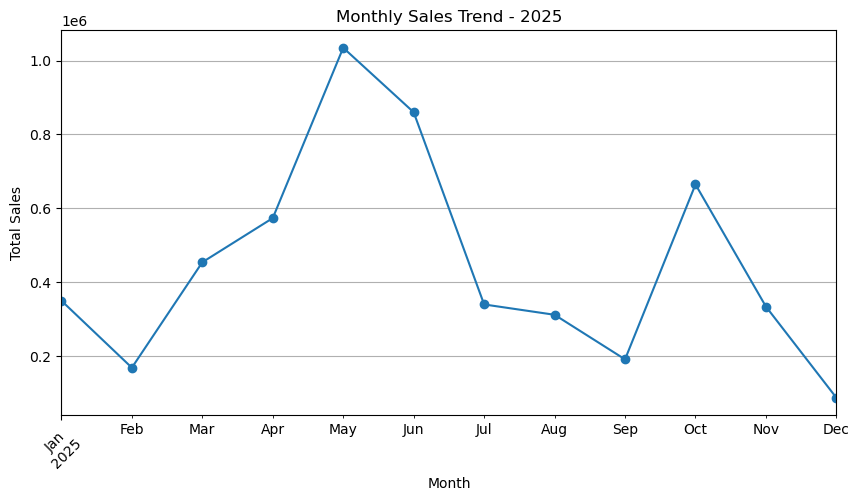

In [156]:
import matplotlib.pyplot as plt

monthly_analysis['Total_Sales'].plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Monthly Sales Trend - 2025'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

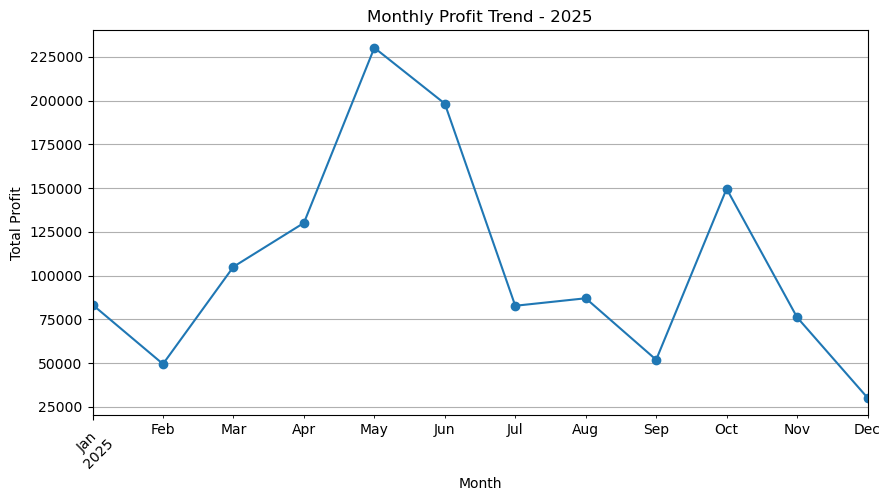

In [157]:
monthly_analysis['Total_Profit'].plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Monthly Profit Trend - 2025'
)

plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [158]:
monthly_analysis['Profit_Margin_%'] = (
    monthly_analysis['Total_Profit']
    / monthly_analysis['Total_Sales']
) * 100

monthly_analysis

,Total_Orders,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Order_Date,,,,,
2025-01,12,350800,83350,34,23.759977
2025-02,17,169640,49470,43,29.161754
2025-03,15,454660,105030,45,23.100779
2025-04,17,574040,130070,55,22.658700
2025-05,26,1034440,230170,76,22.250686
2025-06,21,860100,198250,71,23.049645
2025-07,15,340600,82750,53,24.295361
2025-08,18,312660,87030,63,27.835348
2025-09,16,192180,51890,43,27.000728


In [159]:
df.to_excel('Sales_Dataset_Export.xlsx', index = False)

In [160]:
df.to_excel(
    r'C:\Users\naved\OneDrive\Desktop\Project\RETAIL-001\data\raw\Sales_Dataset_Export.xlsx',
    index=False
)

In [161]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Unit_Cost', 'Sales', 'Profit', 'Calculated_Sales',
       'Calculated_Profit'],
      dtype='object')

In [122]:
df['Profit_Margin_%'] = (df['Profit'] / df['Sales']) * 100

In [123]:
df.columns

Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Unit_Cost', 'Sales', 'Profit', 'Calculated_Sales',
       'Calculated_Profit', 'Profit_Margin_%'],
      dtype='object')